# Проверка библиотек и импорты

In [1]:
import importlib

libs = {
    "torch":          "PyTorch",
    "torchvision":    "TorchVision",
    "PIL":            "Pillow",
    "matplotlib":     "Matplotlib",
    "numpy":          "NumPy",
    "pandas":         "Pandas",
}
for pkg, name in libs.items():
    try:
        mod = importlib.import_module(pkg)
        ver = getattr(mod, "__version__", "?")
        print(f"[OK]  {name}: {ver}")
    except ImportError:
        print(f"[НЕТ] {name}: установите через pip")

[OK]  PyTorch: 2.2.2+rocm5.7


/home/abonentvneseti/.pyenv/versions/3.11.16/lib/python3.11/site-packages/transformers/utils/generic.py:441: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


[OK]  TorchVision: 0.17.2+rocm5.7
[OK]  Pillow: 12.3.0
[OK]  Matplotlib: 3.9.0
[OK]  NumPy: 1.26.4
[OK]  Pandas: 2.2.2


In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random, time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Устройство: cuda


# Загрузка CIFAR-10

In [3]:
raw_train = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=True, transform=None
)
raw_test = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=True, transform=None
)
class_names = raw_train.classes

print(f"Train: {len(raw_train)} изображений")
print(f"Test:  {len(raw_test)} изображений")
print(f"Классы: {class_names}")

Files already downloaded and verified
Files already downloaded and verified
Train: 50000 изображений
Test:  10000 изображений
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# Модель

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

_m = SimpleCNN()
print(f"Параметров: {sum(p.numel() for p in _m.parameters()):,}")
del _m

Параметров: 141,354


In [5]:
def train_model(model, train_loader, test_loader,
                epochs=15, lr=1e-3, device=device,
                seed=42, name="model"):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    train_losses, train_accs, test_accs, epoch_times = [], [], [], []
    start_all = time.time()

    print(f"{name}")
    for epoch in range(epochs):
        t0 = time.time()

        model.train()
        total_loss, correct_tr, total_tr = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct_tr += (out.argmax(1) == labels).sum().item()
            total_tr += imgs.size(0)
        scheduler.step()

        avg_loss  = total_loss / total_tr
        train_acc = correct_tr / total_tr

        model.eval()
        correct_te, total_te = 0, 0
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            pred = model(imgs).argmax(1)
            correct_te += (pred == labels).sum().item()
            total_te += labels.size(0)
        test_acc = correct_te / total_te

        dt = time.time() - t0
        train_losses.append(avg_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        epoch_times.append(dt)

        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"loss={avg_loss:.4f} | "
              f"train_acc={train_acc:.4f} | "
              f"test_acc={test_acc:.4f} | "
              f"time={dt:.1f}s")

    total_time = time.time() - start_all
    print(f"[{name}] Финальное время обучения: {total_time:.1f} сек")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            all_preds.append(model(imgs).argmax(1).cpu().numpy())
            all_labels.append(labels.numpy())
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_labels)

    cm = np.zeros((10, 10), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1

    return {
        "name":            name,
        "model":           model,
        "train_losses":    train_losses,
        "train_accs":      train_accs,
        "test_accs":       test_accs,
        "epoch_times":     epoch_times,
        "total_time":      total_time,
        "cm":              cm,
        "final_train_acc": train_accs[-1],
        "final_test_acc":  test_accs[-1],
    }

In [6]:
def plot_experiment(res):
    name = res["name"]
    epochs = range(1, len(res["train_losses"]) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs, res["train_losses"], marker="o", color="tab:red")
    axes[0].set_title(f"{name}: Loss")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("loss")
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, res["train_accs"], marker="o", label="train")
    axes[1].plot(epochs, res["test_accs"],  marker="s", label="test")
    axes[1].set_title(f"{name}: Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    cm = res["cm"]
    im = axes[2].imshow(cm, cmap="Blues")
    axes[2].set_title(f"{name}: Confusion matrix (test)")
    axes[2].set_xlabel("predicted")
    axes[2].set_ylabel("true")
    axes[2].set_xticks(range(10))
    axes[2].set_yticks(range(10))
    axes[2].set_xticklabels(class_names, rotation=90, fontsize=7)
    axes[2].set_yticklabels(class_names, fontsize=7)
    for i in range(10):
        for j in range(10):
            axes[2].text(j, i, cm[i, j], ha="center", va="center",
                         fontsize=6,
                         color="black" if cm[i, j] < cm.max() / 2 else "white")
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.show()

    print(f"[{name}] Финальное время обучения: {res['total_time']:.1f} сек")
    print(f"[{name}] Финальная train accuracy: {res['final_train_acc']:.4f}")
    print(f"[{name}] Финальная test accuracy: {res['final_test_acc']:.4f}")

# Обучение без аугментаций

Без аугментаций
Epoch  1/15 | loss=1.2752 | train_acc=0.5393 | test_acc=0.6025 | time=11.9s
Epoch  2/15 | loss=0.9113 | train_acc=0.6788 | test_acc=0.6099 | time=11.3s
Epoch  3/15 | loss=0.7675 | train_acc=0.7304 | test_acc=0.6705 | time=11.3s
Epoch  4/15 | loss=0.6719 | train_acc=0.7665 | test_acc=0.6980 | time=11.3s
Epoch  5/15 | loss=0.5962 | train_acc=0.7927 | test_acc=0.7427 | time=11.3s
Epoch  6/15 | loss=0.5367 | train_acc=0.8167 | test_acc=0.7243 | time=11.3s
Epoch  7/15 | loss=0.4757 | train_acc=0.8377 | test_acc=0.7725 | time=11.3s
Epoch  8/15 | loss=0.4262 | train_acc=0.8542 | test_acc=0.7885 | time=11.3s
Epoch  9/15 | loss=0.3783 | train_acc=0.8732 | test_acc=0.7743 | time=11.4s
Epoch 10/15 | loss=0.3363 | train_acc=0.8884 | test_acc=0.8060 | time=11.3s
Epoch 11/15 | loss=0.3010 | train_acc=0.9024 | test_acc=0.8122 | time=11.3s
Epoch 12/15 | loss=0.2676 | train_acc=0.9183 | test_acc=0.8082 | time=11.4s
Epoch 13/15 | loss=0.2450 | train_acc=0.9258 | test_acc=0.8163 | time=11

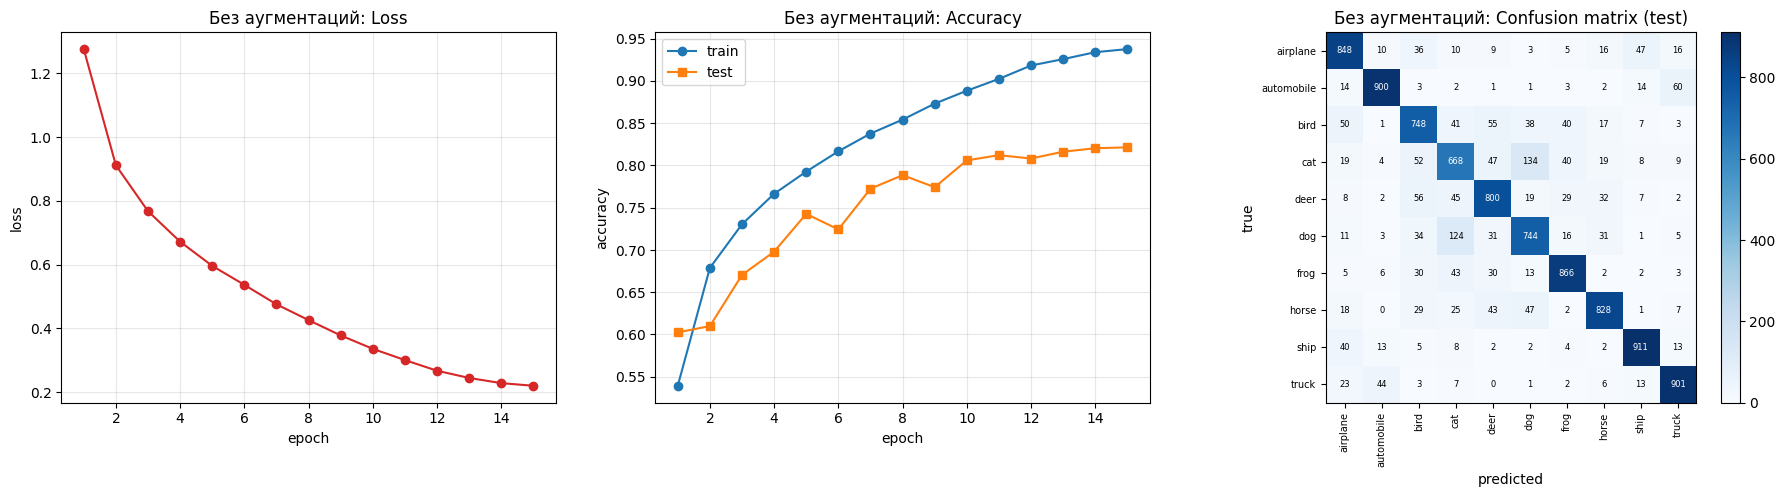

[Без аугментаций] Финальное время обучения: 170.5 сек
[Без аугментаций] Финальная train accuracy: 0.9377
[Без аугментаций] Финальная test accuracy: 0.8214


In [7]:
mean_cifar = (0.4914, 0.4822, 0.4465)
std_cifar  = (0.2470, 0.2435, 0.2616)

transform_none = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_cifar, std=std_cifar),
])

train_ds_none = torchvision.datasets.CIFAR10(
    root="./cifar", train=True,  download=False, transform=transform_none
)
test_ds = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=False, transform=transform_none
)

train_loader_none = DataLoader(train_ds_none, batch_size=128, shuffle=True,  num_workers=0)
test_loader       = DataLoader(test_ds,      batch_size=256, shuffle=False, num_workers=0)

res_none = train_model(
    SimpleCNN(), train_loader_none, test_loader,
    epochs=15, lr=1e-3, name="Без аугментаций"
)
plot_experiment(res_none)

# Все аугментации

Crop+Flip+ColorJitter
Epoch  1/15 | loss=1.4159 | train_acc=0.4846 | test_acc=0.5313 | time=27.3s
Epoch  2/15 | loss=1.0445 | train_acc=0.6308 | test_acc=0.5679 | time=27.2s
Epoch  3/15 | loss=0.8970 | train_acc=0.6857 | test_acc=0.6493 | time=27.1s
Epoch  4/15 | loss=0.8026 | train_acc=0.7215 | test_acc=0.6844 | time=27.2s
Epoch  5/15 | loss=0.7390 | train_acc=0.7441 | test_acc=0.7151 | time=27.0s
Epoch  6/15 | loss=0.6845 | train_acc=0.7638 | test_acc=0.7517 | time=27.1s
Epoch  7/15 | loss=0.6399 | train_acc=0.7791 | test_acc=0.7576 | time=27.1s
Epoch  8/15 | loss=0.6060 | train_acc=0.7911 | test_acc=0.7799 | time=27.3s
Epoch  9/15 | loss=0.5716 | train_acc=0.8049 | test_acc=0.7840 | time=27.2s
Epoch 10/15 | loss=0.5495 | train_acc=0.8115 | test_acc=0.7840 | time=27.3s
Epoch 11/15 | loss=0.5275 | train_acc=0.8198 | test_acc=0.8036 | time=27.3s
Epoch 12/15 | loss=0.5043 | train_acc=0.8271 | test_acc=0.8133 | time=27.3s
Epoch 13/15 | loss=0.4913 | train_acc=0.8309 | test_acc=0.8159 | t

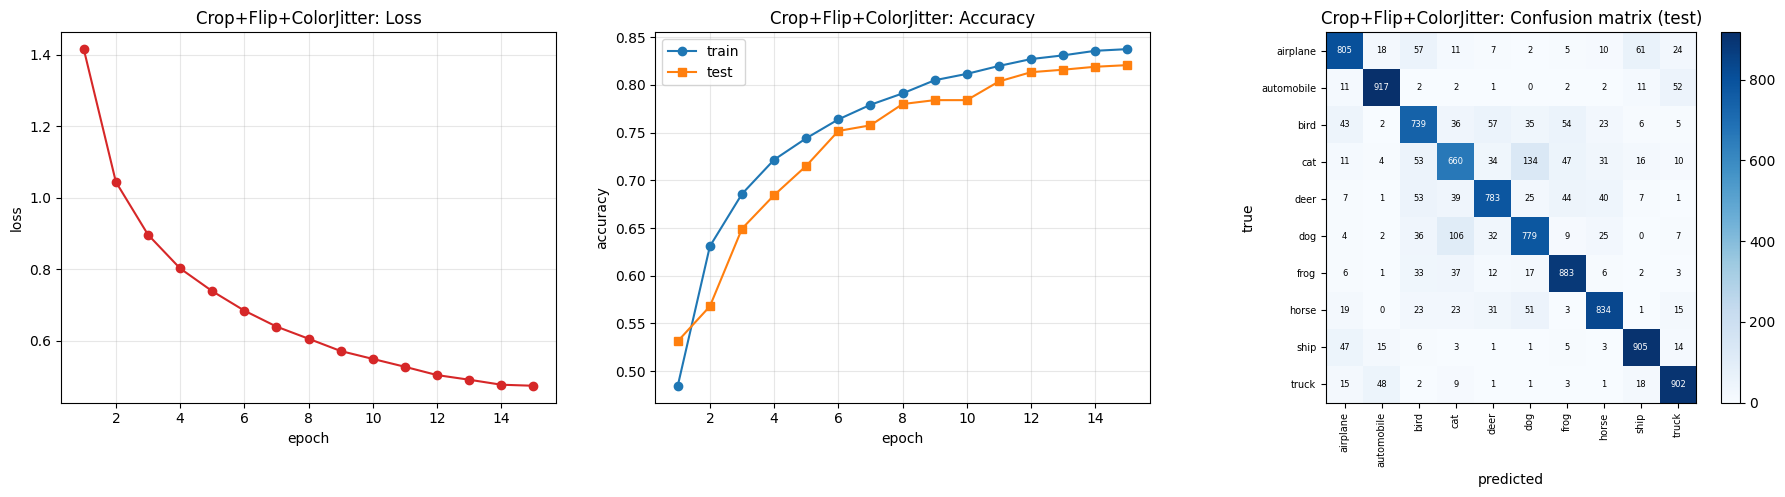

[Crop+Flip+ColorJitter] Финальное время обучения: 408.4 сек
[Crop+Flip+ColorJitter] Финальная train accuracy: 0.8375
[Crop+Flip+ColorJitter] Финальная test accuracy: 0.8207


In [8]:
transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_cifar, std=std_cifar),
])

train_ds_aug = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=False, transform=transform_aug
)
train_loader_aug = DataLoader(train_ds_aug, batch_size=128, shuffle=True, num_workers=0)

res_aug = train_model(
    SimpleCNN(), train_loader_aug, test_loader,
    epochs=15, lr=1e-3, name="Crop+Flip+ColorJitter"
)
plot_experiment(res_aug)

# Все, кроме ColorJitter

Crop+Flip (без ColorJitter)
Epoch  1/15 | loss=1.3690 | train_acc=0.5030 | test_acc=0.5706 | time=14.9s
Epoch  2/15 | loss=0.9978 | train_acc=0.6469 | test_acc=0.6380 | time=14.8s
Epoch  3/15 | loss=0.8565 | train_acc=0.6993 | test_acc=0.6862 | time=14.9s
Epoch  4/15 | loss=0.7606 | train_acc=0.7334 | test_acc=0.6915 | time=15.2s
Epoch  5/15 | loss=0.7039 | train_acc=0.7564 | test_acc=0.7215 | time=15.1s
Epoch  6/15 | loss=0.6508 | train_acc=0.7751 | test_acc=0.7531 | time=15.2s
Epoch  7/15 | loss=0.6115 | train_acc=0.7860 | test_acc=0.7493 | time=15.9s
Epoch  8/15 | loss=0.5765 | train_acc=0.8006 | test_acc=0.7584 | time=17.0s
Epoch  9/15 | loss=0.5441 | train_acc=0.8131 | test_acc=0.7819 | time=17.4s
Epoch 10/15 | loss=0.5133 | train_acc=0.8226 | test_acc=0.7833 | time=17.5s
Epoch 11/15 | loss=0.4966 | train_acc=0.8317 | test_acc=0.8142 | time=17.0s
Epoch 12/15 | loss=0.4764 | train_acc=0.8375 | test_acc=0.8141 | time=17.1s
Epoch 13/15 | loss=0.4622 | train_acc=0.8404 | test_acc=0.82

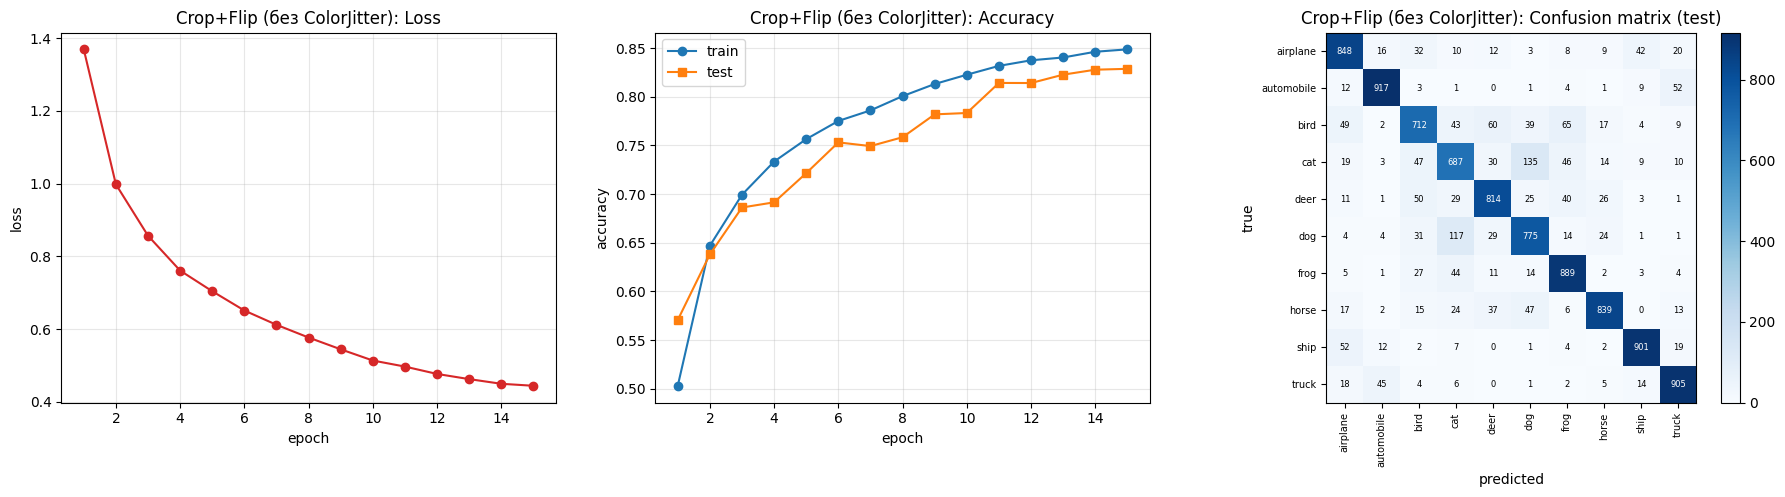

[Crop+Flip (без ColorJitter)] Финальное время обучения: 242.8 сек
[Crop+Flip (без ColorJitter)] Финальная train accuracy: 0.8487
[Crop+Flip (без ColorJitter)] Финальная test accuracy: 0.8287


In [9]:
transform_nojitter = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_cifar, std=std_cifar),
])

train_ds_noj = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=False, transform=transform_nojitter
)
train_loader_noj = DataLoader(train_ds_noj, batch_size=128, shuffle=True, num_workers=0)

res_noj = train_model(
    SimpleCNN(), train_loader_noj, test_loader,
    epochs=15, lr=1e-3, name="Crop+Flip (без ColorJitter)"
)
plot_experiment(res_noj)

# Итог

In [10]:
all_results = [res_none, res_aug, res_noj]

summary = pd.DataFrame({
    "Эксперимент":     [r["name"] for r in all_results],
    "Train accuracy":  [r["final_train_acc"] for r in all_results],
    "Test accuracy":   [r["final_test_acc"]  for r in all_results],
    "Время, сек":      [r["total_time"]      for r in all_results],
})
summary["Delta test к baseline"] = summary["Test accuracy"] - summary["Test accuracy"].iloc[0]
summary = summary.round({"Train accuracy": 4, "Test accuracy": 4,
                         "Время, сек": 1, "Delta test к baseline": 4})
print(summary.to_string(index=False))

best = max(all_results, key=lambda r: r["final_test_acc"])
print(f"\nЛучший по test accuracy: {best['name']} ({best['final_test_acc']:.4f})")

                Эксперимент  Train accuracy  Test accuracy  Время, сек  Delta test к baseline
            Без аугментаций          0.9377         0.8214       170.5                 0.0000
      Crop+Flip+ColorJitter          0.8375         0.8207       408.4                -0.0007
Crop+Flip (без ColorJitter)          0.8487         0.8287       242.8                 0.0073

Лучший по test accuracy: Crop+Flip (без ColorJitter) (0.8287)


# Выводы

- Без аугментаций модель переобучается.
- Crop + Flip + ColorJitter не дает выигрыша в точности(-0.0007), обучается значительно дольше(в 2.4 раза), но не переобучается.
- Без ColorJitter увеличивается точность немного(+0.0073), разрыв во времени обучения становится менее критичным(в 1.4 дольше). Переобучение не происходит.

Из этих 3х случаев лучше всего будет использовать Crop + Flip.